# Feature Selection

In [73]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import missingno as msno
import scipy
import math

In [74]:
df = pd.read_csv("../data/diabetic_data.csv")
df.columns

Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'payer_code', 'medical_specialty',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1',
       'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted'],
      dtype='str')

In [75]:
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = df.select_dtypes(include=['object']).columns.tolist()

C:\Users\daoke\AppData\Local\Temp\ipykernel_17856\2267733196.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object']).columns.tolist()


In [76]:
# Drop features that will likely not be of interest
num_cols

['encounter_id',
 'patient_nbr',
 'admission_type_id',
 'discharge_disposition_id',
 'admission_source_id',
 'time_in_hospital',
 'num_lab_procedures',
 'num_procedures',
 'num_medications',
 'number_outpatient',
 'number_emergency',
 'number_inpatient',
 'number_diagnoses']

In [78]:
df['discharge_disposition_id'].value_counts()

discharge_disposition_id
1     60234
3     13954
6     12902
18     3691
2      2128
22     1993
11     1642
5      1184
25      989
4       815
7       623
23      412
13      399
14      372
28      139
8       108
15       63
24       48
9        21
17       14
16       11
19        8
10        6
27        5
12        3
20        2
Name: count, dtype: int64

In [72]:
# Remove features we know will be of no relevance based on domain knowledge

remove = ['encounter_id','admission_type_id','discharge_disposition_id', 'admission_source_id']
for column in remove:
    num_cols.remove(column)

In [45]:
cat_cols

# 1st generation when they dropped 1950s
# 2nd generation when they dropped 1980s (tend to come with less side effects than 1st generation + more potent in comparison)


# metformin pill to improve insulin sensitivity
# metformin-rosiglitazone compound med
# metformin-pioglitazone compound med


# repglinide pill same purpose
# nateglinide pill same purpose by a difference mechanism

# chlorpropamide long-acting, first-generation sulfonylurea medication used to lower blood sugar in people with type 2 diabetes
# glimepiride a second-generation oral prescription medication used to lower blood sugar in adults with type 2 diabetes
# glimepiride-pioglitazone

# acethexamide first-generation oral sulfonylurea medication formerly prescribed to manage type 2 diabetes mellitus

# glipizide oral prescription medication used to lower blood sugar in adults with type 2 diabetes mellitus
# glipizide-metformin

# glyburide an oral second-generation sulfonylurea medication prescribed alongside diet and exercise to lower blood sugar in adults with type 2 diabetes
# glyburide-metformin compound

# tolbutamide a first-generation oral sulfonylurea medication used to lower blood sugar in adults with type 2 diabetes mellitus
# pioglitazone an oral prescription medication used alongside diet and exercise to lower blood sugar in adults with type 2 diabetes
# rosiglitazone an oral prescription medication used with diet and exercise to lower blood sugar in adults with type 2 diabetes mellitus
# acarbose an alpha-glucosidase inhibitor used to treat type 2 diabetes by slowing down the digestion and absorption of carbohydrates in the gut to prevent high blood sugar spikes after meals
# miglitol an oral alpha-glucosidase inhibitor prescribed to manage blood sugar levels in adults with type 2 diabetes mellitus.
# troglitzaone a first-generation thiazolidinedione oral antidiabetic medication that was approved to treat type 2 diabetes mellitus, but was later withdrawn from the market in March 2000 due to severe liver toxicity
# tolazamide an oral first-generation sulfonylurea medication used to lower blood sugar levels in adults with type 2 diabetes mellitus
# examide a brand-name prescription medication containing the active ingredient torsemide
# citoglipton prescription oral medication used to improve blood sugar control in adults with type 2 diabetes




# change

# diabetesMed

['race',
 'gender',
 'age',
 'weight',
 'payer_code',
 'medical_specialty',
 'diag_1',
 'diag_2',
 'diag_3',
 'max_glu_serum',
 'A1Cresult',
 'metformin',
 'repaglinide',
 'nateglinide',
 'chlorpropamide',
 'glimepiride',
 'acetohexamide',
 'glipizide',
 'glyburide',
 'tolbutamide',
 'pioglitazone',
 'rosiglitazone',
 'acarbose',
 'miglitol',
 'troglitazone',
 'tolazamide',
 'examide',
 'citoglipton',
 'insulin',
 'glyburide-metformin',
 'glipizide-metformin',
 'glimepiride-pioglitazone',
 'metformin-rosiglitazone',
 'metformin-pioglitazone',
 'change',
 'diabetesMed',
 'readmitted']

## Outliers within Numerical Columns

We use 

- scipy.stats.zscore
- sklearn.ensemble.IsolationForest
- seaborn.boxplot


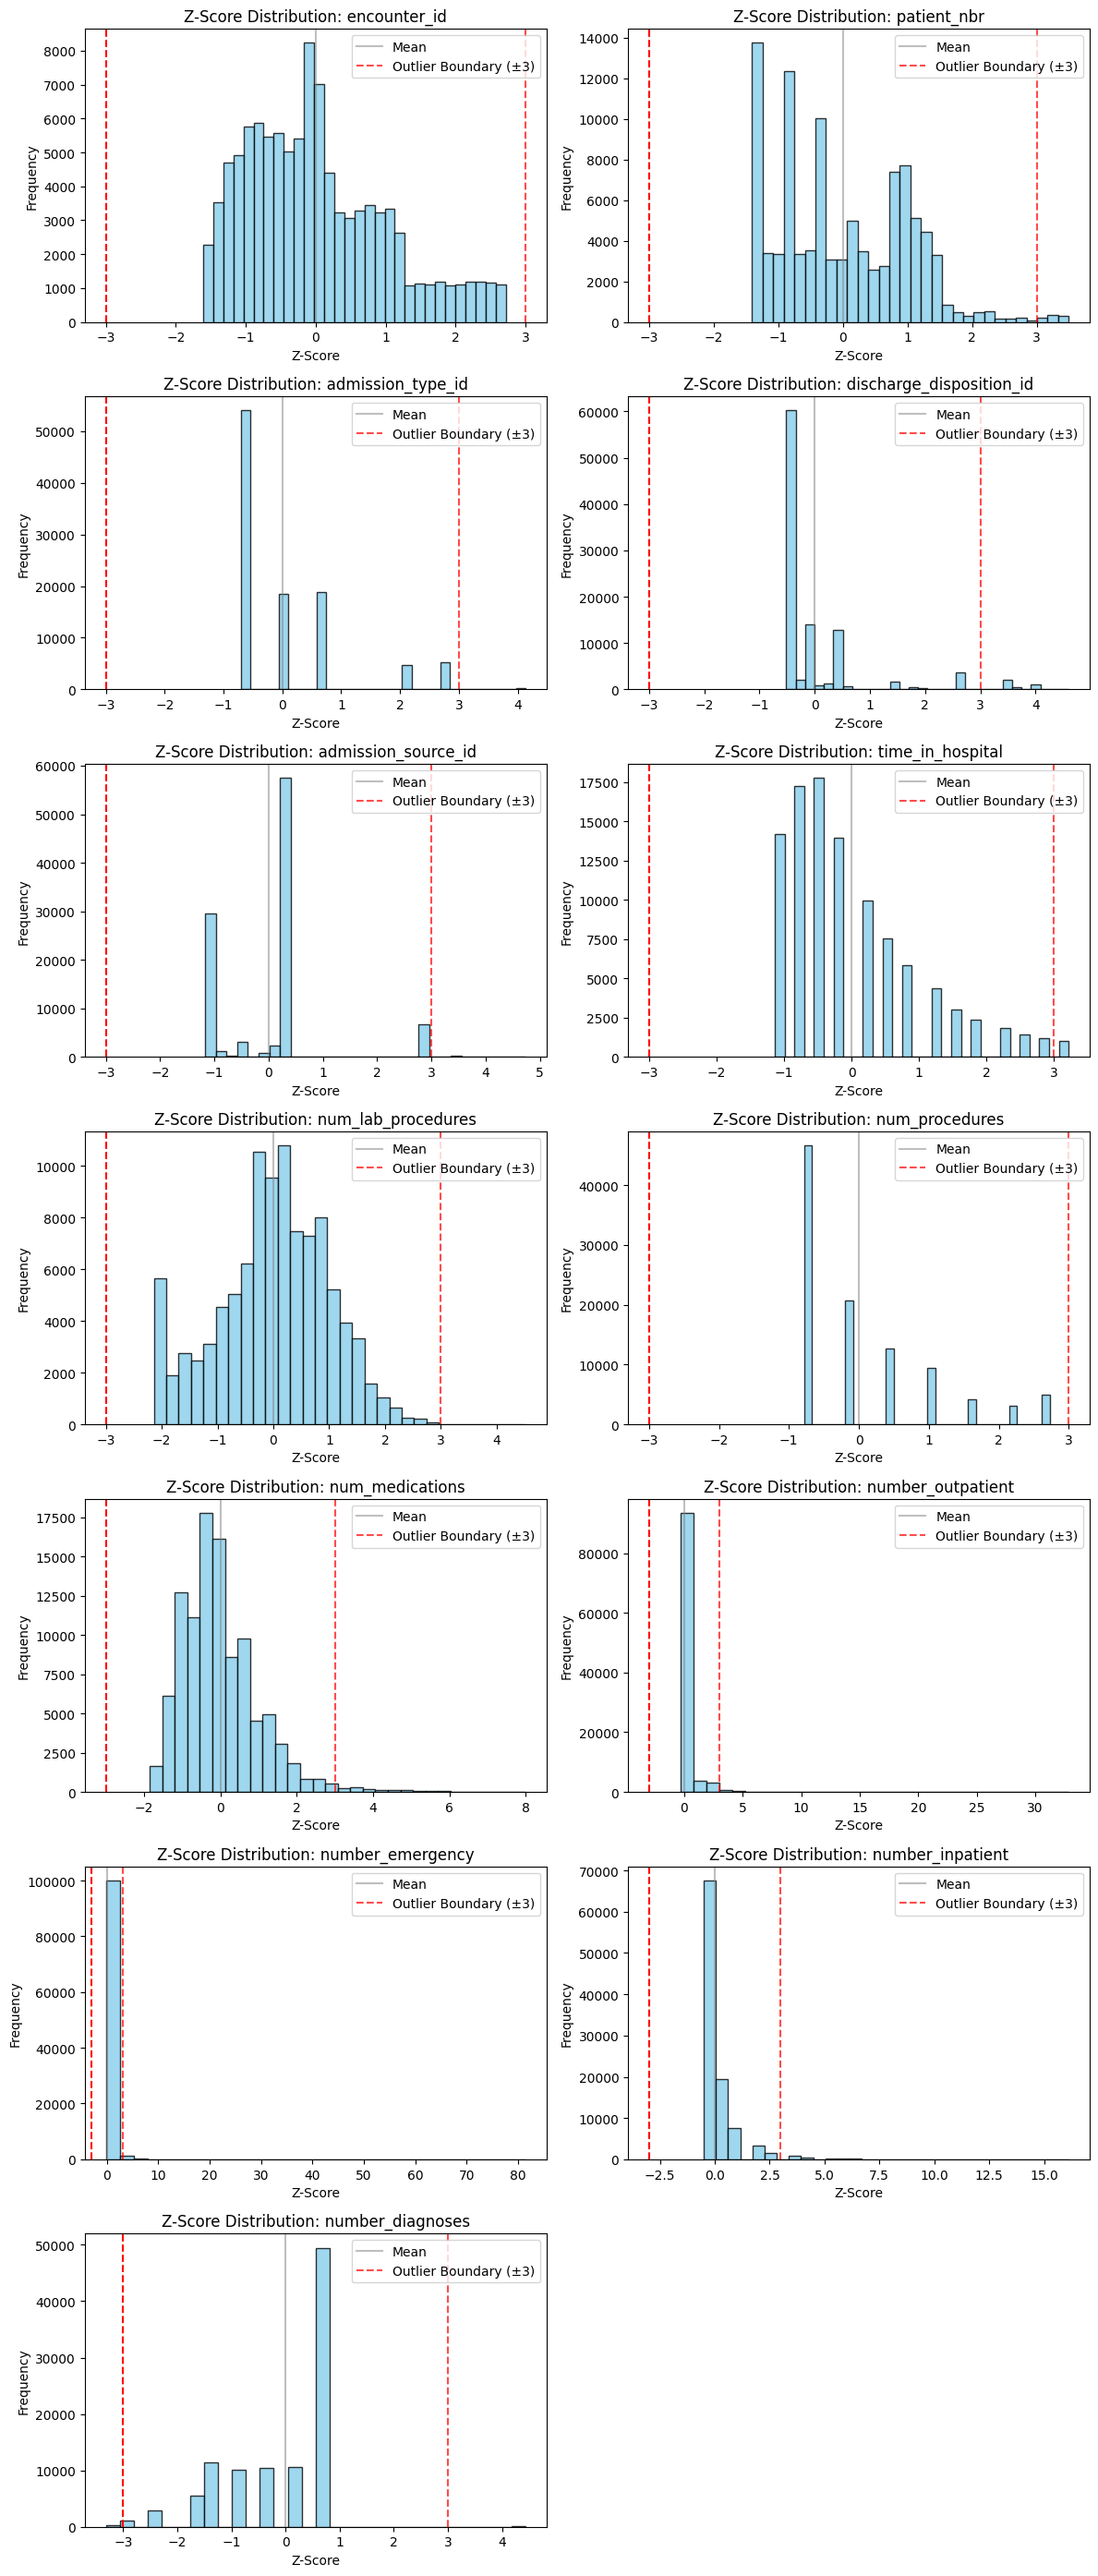

In [ ]:
# Define grid layout (e.g., 2 columns per row)
n_cols = len(num_cols)
ncols_grid = 2
nrows_grid = math.ceil(n_cols / ncols_grid)

# Create the subplot grid
fig, axes = plt.subplots(nrows=nrows_grid, ncols=ncols_grid, figsize=(12, 4 * nrows_grid), squeeze=False)
axes_flat = axes.flatten()

for i, column in enumerate(num_cols):
    ax = axes_flat[i]
    
    # Calculate and plot the z-scores on the specific subplot axis
    z_scores = scipy.stats.zscore(df[column].dropna())
    pd.Series(z_scores).plot(kind='hist', ax=ax, bins=30, color='skyblue', edgecolor='black', alpha=0.8)
    
    # Add context lines
    ax.axvline(0, color='gray', linestyle='-', alpha=0.5, label='Mean')
    ax.axvline(3, color='red', linestyle='--', alpha=0.7, label='Outlier Boundary (±3)')
    ax.axvline(-3, color='red', linestyle='--')
    
    ax.set_title(f'Z-Score Distribution: {column}')
    ax.set_xlabel('Z-Score')
    ax.set_ylabel('Frequency')
    ax.legend(loc='upper right')

# Remove any empty trailing subplots if the grid has leftover spaces
for j in range(i + 1, len(axes_flat)):
    fig.delaxes(axes_flat[j])

plt.tight_layout()
plt.show()